In [ ]:
from pathlib import Path
import sys, pickle, json, random
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import roc_auc_score
from scipy.stats import ttest_rel, wilcoxon

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SEED = 2025 # test diff seeds
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_PATH = MODEL_DIR / f"v6_seed_best.pt"
TEST_PATH = PROJECT_ROOT / "data" / "processed" / "quantum" / "test.pkl"
RESULTS_DIR = PROJECT_ROOT / "notebooks" / "stats_q4"
FIGURE_DIR = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Current V6 checkpoint:", MODEL_PATH)
print("Current sequence test data:", TEST_PATH)
print("Results:", RESULTS_DIR)

In [ ]:
required_files = [TEST_PATH]
if not MODEL_PATH.exists():
    for fallback_seed in [42]:
        fallback = MODEL_DIR / f"v6_seed_{fallback_seed}_best.pt"
        if fallback.exists():
            MODEL_PATH = fallback
            print(f"Seed-{SEED} checkpoint not found; using {MODEL_PATH.name}")
            break
required_files.append(MODEL_PATH)
for path in required_files:
    print(f"{'✓' if path.exists() else '✗'} {path}")
if not all(path.exists() for path in required_files):
    raise FileNotFoundError("Missing checkpoint or dataset.")

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
print(f"Seed: {SEED}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

In [5]:
with open(TEST_PATH, "rb") as f:
    test_samples = pickle.load(f)
print(f"Test records: {len(test_samples):,}")
print("First sample keys:")
print(sorted(test_samples[0].keys()))
required = {"audio_hidden_states", "text_hidden_states", "participant_id", "label"}
missing = required - set(test_samples[0])
if missing:
    raise KeyError(f"Missing current sequence fields: {sorted(missing)}")
print("✓ Current Stage-C sequence representations detected.")

Test records: 5,081
First sample keys:
['audio_embedding', 'audio_hidden_states', 'confidence', 'duration', 'label', 'participant_id', 'phq8_total', 'split', 'text', 'text_embedding', 'text_hidden_states', 'utterance_id']
✓ Current Stage-C sequence representations detected.


In [6]:
from src.proposed.dataset import QuantumSequenceDataset, collate_fn
from src.proposed.v6.model_v6 import ProposedModelV6
print("✓ Proposed model and dataset imported.")

✓ Proposed model and dataset imported.


In [7]:
test_dataset = QuantumSequenceDataset(TEST_PATH)
test_loader = DataLoader(
    test_dataset, batch_size=8, shuffle=False,
    collate_fn=collate_fn, pin_memory=(device.type == "cuda")
)
print(f"Test records: {len(test_dataset):,}")
print(f"Test batches: {len(test_loader):,}")

Test records: 5,081
Test batches: 636


In [8]:
checkpoint = torch.load(MODEL_PATH, map_location=device)
if "model_state_dict" not in checkpoint:
    raise KeyError("Expected current train_v6.py checkpoint with 'model_state_dict'.")
model = ProposedModelV6(rank=16).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
checkpoint_threshold = checkpoint.get("dev_threshold")
print("✓ Proposed model checkpoint loaded.")
print("Checkpoint seed:", checkpoint.get("seed", "unknown"))
print("Best epoch:", checkpoint.get("epoch", "unknown"))
print("DEV-selected threshold:",
      f"{float(checkpoint_threshold):.3f}" if checkpoint_threshold is not None else "not stored")

✓ Proposed model checkpoint loaded.
Checkpoint seed: 2024
Best epoch: 1
DEV-selected threshold: 0.375


In [9]:
def extract_v6_metrics(model, loader):
    model.eval()
    records = []
    with torch.no_grad():
        for batch in loader:
            audio = batch["audio"].to(device)
            text = batch["text"].to(device)
            audio_mask = batch["audio_mask"].to(device)
            text_mask = batch["text_mask"].to(device)
            out = model(audio, text, audio_mask, text_mask)
            prob = torch.softmax(out["logits"], dim=-1)[:, 1].cpu().numpy()
            labels = batch["labels"].cpu().numpy()
            pids = batch["participant_ids"]
            uids = batch["utterance_ids"]
            phq = batch["phq8_totals"].cpu().numpy()
            keys = [
                "sadi","fidelity","trace_distance","audio_entropy","text_entropy",
                "audio_purity","text_purity","joint_entropy_pre",
                "joint_entropy_post","qmi"
            ]
            vals = {k: out[k].cpu().numpy() for k in keys}
            rho_t = out["rho_text_post"].cpu().numpy()
            rho_a = out["rho_audio_post"].cpu().numpy()
            for i in range(len(labels)):
                records.append({
                    "participant_id": str(pids[i]),
                    "utterance_id": str(uids[i]),
                    "label": int(labels[i]),
                    "phq8_total": float(phq[i]),
                    "probability": float(prob[i]),
                    "discordance": float(vals["sadi"][i]),
                    "fidelity": float(vals["fidelity"][i]),
                    "trace_distance": float(vals["trace_distance"][i]),
                    "audio_entropy": float(vals["audio_entropy"][i]),
                    "text_entropy": float(vals["text_entropy"][i]),
                    "audio_purity": float(vals["audio_purity"][i]),
                    "text_purity": float(vals["text_purity"][i]),
                    "joint_entropy_pre": float(vals["joint_entropy_pre"][i]),
                    "joint_entropy_post": float(vals["joint_entropy_post"][i]),
                    "mutual_information": float(vals["qmi"][i]),
                    "rho_text_post": rho_t[i],
                    "rho_audio_post": rho_a[i],
                })
    return pd.DataFrame(records)

def summarise_participant_level(df):
    metrics = [
        "discordance","fidelity","trace_distance","audio_entropy","text_entropy",
        "audio_purity","text_purity","joint_entropy_pre","joint_entropy_post",
        "mutual_information"
    ]
    agg = {"label":"first","phq8_total":"first","probability":"mean"}
    agg.update({m:"mean" for m in metrics})
    return (df.groupby("participant_id", as_index=False).agg(agg)
              .sort_values("participant_id").reset_index(drop=True))

def vectorise_density_states(df):
    text = np.stack([np.asarray(x).reshape(-1) for x in df["rho_text_post"]])
    audio = np.stack([np.asarray(x).reshape(-1) for x in df["rho_audio_post"]])
    return text.astype(float), audio.astype(float)

def calculate_classical_distances(df):
    text, audio = vectorise_density_states(df)
    euclidean = np.linalg.norm(text-audio, axis=1)
    cosine = 1.0 - np.sum(text*audio, axis=1) / (
        np.linalg.norm(text, axis=1)*np.linalg.norm(audio, axis=1) + 1e-12
    )
    out = df.copy()
    out["euclidean_distance"] = euclidean
    out["cosine_distance"] = cosine
    return out

class InMemoryQuantumSequenceDataset(Dataset):
    def __init__(self, samples): self.samples = samples
    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        x = self.samples[idx]
        return {
            "audio": torch.tensor(np.asarray(x["audio_hidden_states"], dtype=np.float32)),
            "text": torch.tensor(np.asarray(x["text_hidden_states"], dtype=np.float32)),
            "label": torch.tensor(int(x["label"]), dtype=torch.long),
            "participant_id": str(x["participant_id"]),
            "utterance_id": str(x.get("utterance_id", f"perturb_{idx}")),
            "phq8_total": torch.tensor(float(x.get("phq8_total", np.nan)), dtype=torch.float32),
        }

def collate_mismatch_fn(batch):
    B=len(batch); al=[x["audio"].shape[0] for x in batch]; tl=[x["text"].shape[0] for x in batch]
    A=torch.zeros(B,max(al),768); T=torch.zeros(B,max(tl),768)
    am=torch.zeros(B,max(al),dtype=torch.bool); tm=torch.zeros(B,max(tl),dtype=torch.bool)
    labels=[]; pids=[]; uids=[]; phq=[]
    for i,x in enumerate(batch):
        a,t=x["audio"],x["text"]; A[i,:a.shape[0]]=a; T[i,:t.shape[0]]=t
        am[i,:a.shape[0]]=True; tm[i,:t.shape[0]]=True
        labels.append(x["label"]); pids.append(x["participant_id"]); uids.append(x["utterance_id"]); phq.append(x["phq8_total"])
    return {"audio":A,"text":T,"audio_mask":am,"text_mask":tm,
            "lengths_audio":torch.tensor(al),"lengths_text":torch.tensor(tl),
            "labels":torch.stack(labels),"participant_ids":pids,"utterance_ids":uids,
            "phq8_totals":torch.stack(phq)}

In [ ]:
correct_full = extract_v6_metrics(model, test_loader)
correct_participant = summarise_participant_level(correct_full)
print(f"Correctly paired records: {len(correct_full):,}")
print(f"Correct-pair participants: {len(correct_participant):,}")
display(correct_full.head())

In [11]:
correct_full.to_pickle(RESULTS_DIR / "correct_pair_metrics.pkl")
correct_full.drop(columns=["rho_text_post","rho_audio_post"]).to_csv(
    RESULTS_DIR / "correct_pair_metrics.csv", index=False
)
correct_participant.to_csv(
    RESULTS_DIR / "correct_pair_participant_metrics.csv", index=False
)
print("✓ Correct-pair metrics saved.")

✓ Correct-pair metrics saved.


In [12]:
def cross_participant_mismatch(samples, seed=2025):
    rng = np.random.default_rng(seed)
    pids = np.asarray([str(x["participant_id"]) for x in samples])
    unique = np.unique(pids)
    if len(unique) < 2:
        raise ValueError("Need at least two participants.")
    for _ in range(100):
        perm = rng.permutation(unique)
        mapping = dict(zip(unique, perm))
        source_pids = np.asarray([mapping[p] for p in pids])
        if np.all(source_pids != pids):
            break
    else:
        raise RuntimeError("Could not construct fixed-point-free pairing.")
    by_pid={}
    for x in samples: by_pid.setdefault(str(x["participant_id"]), []).append(x)
    out=[]
    for x, src_pid in zip(samples, source_pids):
        src = by_pid[str(src_pid)][int(rng.integers(len(by_pid[str(src_pid)])))]
        y=dict(x)
        y["audio_hidden_states"]=np.asarray(src["audio_hidden_states"]).copy()
        y["_audio_source_participant"]=str(src_pid)
        out.append(y)
    return out

In [13]:
mismatched_samples = cross_participant_mismatch(test_samples, seed=SEED)
same = sum(str(x["participant_id"]) == str(x["_audio_source_participant"]) for x in mismatched_samples)
print(f"Mismatched records: {len(mismatched_samples):,}")
print(f"Same-participant audio pairs: {same}")
if same: raise AssertionError("Mismatch contains same-participant audio.")
print("✓ Cross-participant mismatch passed.")

Mismatched records: 5,081
Same-participant audio pairs: 0
✓ Cross-participant mismatch passed.


In [14]:
unchanged=0
for a,b in zip(test_samples,mismatched_samples):
    if np.array_equal(np.asarray(a["audio_hidden_states"]), np.asarray(b["audio_hidden_states"])):
        unchanged += 1
print(f"Unchanged audio observations: {unchanged}")
if unchanged == len(test_samples):
    raise AssertionError("No audio was changed.")

Unchanged audio observations: 0


In [15]:
mismatched_dataset = InMemoryQuantumSequenceDataset(mismatched_samples)
mismatched_loader = DataLoader(
    mismatched_dataset, batch_size=8, shuffle=False,
    collate_fn=collate_mismatch_fn, pin_memory=(device.type=="cuda")
)
print(f"Mismatched samples: {len(mismatched_dataset):,}")

Mismatched samples: 5,081


In [ ]:
mismatched_full = extract_v6_metrics(model, mismatched_loader)
mismatched_participant = summarise_participant_level(mismatched_full)
print(f"Mismatched records: {len(mismatched_full):,}")
print(f"Mismatched participants: {len(mismatched_participant):,}")
display(mismatched_full.head())

In [17]:
correct_df=correct_participant.copy()
mismatched_df=mismatched_participant.copy()
correct_df["condition"]="Correct Pair"
mismatched_df["condition"]="Cross-Participant Mismatch"
combined_df=pd.concat([correct_df,mismatched_df],ignore_index=True)
print(combined_df["condition"].value_counts())

condition
Correct Pair                  56
Cross-Participant Mismatch    56
Name: count, dtype: int64


In [18]:
combined_df.to_csv(RESULTS_DIR/"correct_vs_mismatched_participant_metrics.csv",index=False)
mismatched_full.to_pickle(RESULTS_DIR/"mismatched_pair_metrics.pkl")
print("✓ Combined participant-level metrics saved.")

✓ Combined participant-level metrics saved.


In [19]:
quantum_metrics=["discordance","fidelity","trace_distance","audio_entropy","text_entropy",
"audio_purity","text_purity","joint_entropy_post","mutual_information"]
rows=[]
for m in quantum_metrics:
    a=correct_df[m].values; b=mismatched_df[m].values
    rows.append({"Metric":m,"Correct Mean":np.mean(a),"Correct SD":np.std(a,ddof=1),
                 "Mismatched Mean":np.mean(b),"Mismatched SD":np.std(b,ddof=1)})
quantum_summary=pd.DataFrame(rows)
display(quantum_summary)

,Metric,Correct Mean,Correct SD,Mismatched Mean,Mismatched SD
0,discordance,0.990150,0.003673,0.990920,0.002094
1,fidelity,0.009850,0.003673,0.009080,0.002094
2,trace_distance,0.995105,0.001836,0.995492,0.001042
3,audio_entropy,0.002365,0.000284,0.002457,0.000378
4,text_entropy,0.048647,0.018948,0.049942,0.019615
5,audio_purity,0.999551,0.000060,0.999531,0.000079
6,text_purity,0.981521,0.008797,0.980448,0.009586
7,joint_entropy_post,0.050935,0.018858,0.052322,0.019638
8,mutual_information,0.000076,0.000008,0.000077,0.000007


In [ ]:
rows=[]
for m in quantum_metrics:
    a=correct_df[m].values; b=mismatched_df[m].values; d=b-a
    t,p=ttest_rel(b,a)
    try: w,wp=wilcoxon(b,a,alternative="two-sided")
    except ValueError: w,wp=np.nan,np.nan
    rows.append({"Metric":m,"Mean Correct":np.mean(a),"Mean Mismatched":np.mean(b),
                 "Mean Difference":np.mean(d),"Paired t-statistic":t,"Paired t-test p":p,
                 "Wilcoxon statistic":w,"Wilcoxon p":wp})
paired_tests=pd.DataFrame(rows)
display(paired_tests)

In [ ]:
rows=[]
for m in quantum_metrics:
    d=mismatched_df[m].values-correct_df[m].values
    sd=np.std(d,ddof=1)
    rows.append({"Metric":m,"Mean Difference":np.mean(d),"SD Difference":sd,
                 "Paired Cohen d":np.mean(d)/sd if sd>0 else np.nan})
effect_df=pd.DataFrame(rows)
display(effect_df)

In [22]:
def bootstrap_mean_difference_ci(x,y,n_bootstrap=5000,seed=2025):
    rng=np.random.default_rng(seed)
    d=np.asarray(x)-np.asarray(y); n=len(d)
    means=np.empty(n_bootstrap)
    for i in range(n_bootstrap):
        means[i]=np.mean(rng.choice(d,size=n,replace=True))
    lo,hi=np.percentile(means,[2.5,97.5])
    return np.mean(d),lo,hi

In [ ]:
rows=[]
for m in quantum_metrics:
    md,lo,hi=bootstrap_mean_difference_ci(mismatched_df[m].values,correct_df[m].values,seed=SEED)
    rows.append({"Metric":m,"Mean Difference":md,"95% CI Lower":lo,"95% CI Upper":hi})
bootstrap_ci_df=pd.DataFrame(rows)
display(bootstrap_ci_df)

In [24]:
quantum_statistical_results=(paired_tests.merge(effect_df,on="Metric",how="left",suffixes=("","_effect"))
    .merge(bootstrap_ci_df,on="Metric",how="left",suffixes=("","_ci")))
display(quantum_statistical_results)

,Metric,Mean Correct,Mean Mismatched,Mean Difference,Paired t-statistic,Paired t-test p,Wilcoxon statistic,Wilcoxon p,Mean Difference_effect,SD Difference,Paired Cohen d,Mean Difference_ci,95% CI Lower,95% CI Upper
0,discordance,0.990150,0.990920,7.699323e-04,1.841198,0.070988,647.0,0.218054,7.699323e-04,0.003129,0.246040,7.699323e-04,-5.809508e-07,1.600391e-03
1,fidelity,0.009850,0.009080,-7.699318e-04,-1.841197,0.070988,647.0,0.218054,-7.699318e-04,0.003129,-0.246040,-7.699318e-04,-1.600390e-03,5.818231e-07
2,trace_distance,0.995105,0.995492,3.873616e-04,1.846349,0.070225,648.0,0.221117,3.873616e-04,0.001570,0.246729,3.873616e-04,2.071747e-06,8.057936e-04
3,audio_entropy,0.002365,0.002457,9.280657e-05,4.303239,0.000070,343.0,0.000206,9.280657e-05,0.000161,0.575044,9.280657e-05,5.037693e-05,1.339025e-04
4,text_entropy,0.048647,0.049942,1.295311e-03,0.401885,0.689326,726.0,0.556995,1.295311e-03,0.024119,0.053704,1.295311e-03,-4.926107e-03,7.496214e-03
5,audio_purity,0.999551,0.999531,-2.051359e-05,-4.566692,0.000028,316.0,0.000084,-2.051359e-05,0.000034,-0.610250,-2.051359e-05,-2.918414e-05,-1.155486e-05
6,text_purity,0.981521,0.980448,-1.073133e-03,-0.695598,0.489609,694.0,0.396250,-1.073133e-03,0.011545,-0.092953,-1.073133e-03,-4.048441e-03,1.870443e-03
7,joint_entropy_post,0.050935,0.052322,1.387194e-03,0.429252,0.669416,725.0,0.551531,1.387194e-03,0.024183,0.057361,1.387194e-03,-4.858599e-03,7.598344e-03
8,mutual_information,0.000076,0.000077,9.235275e-07,0.724927,0.471570,691.0,0.382768,9.235275e-07,0.000010,0.096872,9.235275e-07,-1.552852e-06,3.407141e-06


In [ ]:
# ============================================================
# DeLong AUC + 95% CI for Cross-Modal Mismatch Detection
#
# Requirement:
# Discrimination between matched and mismatched pairs is summarised by AUC with DeLong 95% CIs.
#   1. Implements the non-parametric DeLong variance estimator
#   2. Computes AUC
#   3. Computes 95% CI
#   4. Applies it to the existing participant-level
#      correct-vs-mismatched results

import numpy as np
import pandas as pd
from scipy.stats import norm

# DeLong implementation

def _compute_midrank(x):
    """
    Compute midranks for DeLong's AUC variance estimator.
    """
    x = np.asarray(x, dtype=float)

    order = np.argsort(x)
    sorted_x = x[order]

    midranks = np.empty(len(x), dtype=float)

    start = 0

    while start < len(x):

        end = start + 1

        while end < len(x) and sorted_x[end] == sorted_x[start]:
            end += 1

        midrank = 0.5 * (start + end - 1) + 1

        midranks[order[start:end]] = midrank

        start = end

    return midranks


def delong_auc_variance(y_true, y_score):
    """
    Fast DeLong-style non-parametric estimator for
    ROC-AUC variance.

    Parameters
    ----------
    y_true : array-like
        Binary labels:
            0 = matched
            1 = mismatched

    y_score : array-like
        Continuous mismatch score where larger values
        indicate stronger evidence of mismatch.

    Returns
    -------
    auc : float
        ROC-AUC.

    variance : float
        DeLong variance estimate.
    """

    y_true = np.asarray(y_true, dtype=int)
    y_score = np.asarray(y_score, dtype=float)

    # Remove invalid observations
    valid = np.isfinite(y_true) & np.isfinite(y_score)

    y_true = y_true[valid]
    y_score = y_score[valid]

    # Check binary labels
    classes = np.unique(y_true)

    if not np.array_equal(classes, np.array([0, 1])):
        raise ValueError(
            f"y_true must contain both 0 and 1. "
            f"Found classes: {classes}"
        )

    # Positive = mismatched
    pos_scores = y_score[y_true == 1]
    neg_scores = y_score[y_true == 0]

    m = len(pos_scores)
    n = len(neg_scores)

    if m < 2 or n < 2:
        raise ValueError(
            "DeLong requires at least two positive and two "
            "negative observations."
        )

    # Midranks over all observations
    combined = np.concatenate([pos_scores, neg_scores])

    tx = _compute_midrank(combined[:m])
    ty = _compute_midrank(combined[m:])

    # DeLong formulation
    tz = _compute_midrank(combined)

    auc = (
        np.sum(tz[:m]) - m * (m + 1) / 2
    ) / (m * n)

    # V10 / V01 components
    v01 = (tz[:m] - tx) / n
    v10 = 1.0 - (tz[m:] - ty) / m

    # Sample variances
    s01 = np.var(v01, ddof=1)
    s10 = np.var(v10, ddof=1)

    variance = s01 / m + s10 / n

    return float(auc), float(variance)


def delong_auc_ci(
    y_true,
    y_score,
    confidence=0.95
):
    """
    Calculate ROC-AUC and DeLong confidence interval.
    """

    auc, variance = delong_auc_variance(
        y_true,
        y_score
    )

    se = np.sqrt(max(variance, 0.0))

    alpha = 1.0 - confidence

    z = norm.ppf(1.0 - alpha / 2.0)

    lower = auc - z * se
    upper = auc + z * se

    # AUC must remain within [0, 1]
    lower = max(0.0, lower)
    upper = min(1.0, upper)

    return {
        "AUC": auc,
        "DeLong_SE": se,
        "CI_lower": lower,
        "CI_upper": upper,
    }

# ============================================================
# Prepare participant-level matched / mismatched data
#
# Expects the participant-level dataframe already produced.

_candidate_names = [
    "correct_vs_mismatched_participant_df",
    "correct_vs_mismatched_participant_metrics",
    "participant_comparison_df",
    "q_vs_c_participant_df",
    "participant_df",
]

participant_df = None

for _name in _candidate_names:

    if _name in globals():

        _candidate = globals()[_name]

        if isinstance(_candidate, pd.DataFrame):

            participant_df = _candidate.copy()

            print(
                f"Using existing dataframe: {_name}"
            )

            break


# If no dataframe was found, try loading the uploaded participant-level comparison CSV.

if participant_df is None:

    possible_paths = [
        RESULTS_DIR / "correct_vs_mismatched_participant_metrics.csv",
    ]

    for _path in possible_paths:

        try:

            participant_df = pd.read_csv(_path)

            print(
                f"Loaded participant-level comparison: {_path}"
            )

            break

        except Exception:
            pass


if participant_df is None:

    raise NameError(
        "Could not find the participant-level "
        "matched-vs-mismatched dataframe.\n\n"
        "Set participant_df manually to the dataframe "
        "containing your participant-level matched and "
        "mismatched metrics, then rerun this cell."
    )


print("\nParticipant-level dataframe:")
print("Shape:", participant_df.shape)
print("Columns:")
print(participant_df.columns.tolist())


# ============================================================
# Detect condition column
# ============================================================

condition_candidates = [
    "condition",
    "Condition",
    "pair_condition",
    "pairing_condition",
]

condition_col = None

for c in condition_candidates:

    if c in participant_df.columns:

        condition_col = c
        break


if condition_col is None:

    raise ValueError(
        "Could not identify the condition column.\n"
        "Expected one of: "
        + ", ".join(condition_candidates)
    )


print(
    f"\nCondition column: {condition_col}"
)

print(
    "\nConditions found:"
)

print(
    participant_df[condition_col]
    .value_counts(dropna=False)
)


# ============================================================
# Normalise condition labels
# ============================================================

def _normalise_condition(x):

    s = str(x).strip().lower()

    if (
        "mismatch" in s
        or "mismatched" in s
    ):
        return "Mismatched"

    if (
        "correct" in s
        or "matched" in s
        or "original" in s
    ):
        return "Matched"

    return str(x)


participant_df["_condition_norm"] = (
    participant_df[condition_col]
    .map(_normalise_condition)
)


# Keep only matched / mismatched
auc_df = participant_df[
    participant_df["_condition_norm"].isin(
        ["Matched", "Mismatched"]
    )
].copy()


if auc_df.empty:

    raise ValueError(
        "No Matched/Mismatched rows were found "
        "after condition normalisation."
    )


auc_df["_y_true"] = (
    auc_df["_condition_norm"]
    .map({
        "Matched": 0,
        "Mismatched": 1
    })
)


print(
    "\nAUC sample counts:"
)

print(
    auc_df["_condition_norm"]
    .value_counts()
)


# ============================================================
# Find metric columns
# ============================================================

metric_candidates = {
    "discordance": [
        "discordance",
        "sadi",
        "SADI",
    ],

    "fidelity": [
        "fidelity",
    ],

    "euclidean_distance": [
        "euclidean_distance",
        "euclidean",
    ],

    "cosine_distance": [
        "cosine_distance",
        "cosine",
    ],
}


def find_metric_column(candidates):

    for c in candidates:

        if c in auc_df.columns:
            return c

    return None


metric_columns = {
    metric: find_metric_column(candidates)
    for metric, candidates
    in metric_candidates.items()
}


print(
    "\nDetected metric columns:"
)

for metric, col in metric_columns.items():

    print(
        f"  {metric:20s}: {col}"
    )

# Calculate DeLong AUC + 95% CI

delong_results = []


for metric, column in metric_columns.items():

    if column is None:

        print(
            f"\nSkipping {metric}: column not found."
        )

        continue


    tmp = auc_df[
        ["_y_true", column]
    ].copy()

    tmp[column] = pd.to_numeric(
        tmp[column],
        errors="coerce"
    )

    tmp = tmp.dropna()


    # --------------------------------------------------------
    # Orient score so HIGHER = stronger evidence of mismatch.
    #
    # Discordance:
    #     higher = more mismatch
    #
    # Fidelity:
    #     lower = more mismatch
    #     therefore invert it
    #
    # Euclidean:
    #     higher = more mismatch
    #
    # Cosine distance:
    #     higher = more mismatch
    # --------------------------------------------------------

    if metric == "fidelity":

        score = -tmp[column].to_numpy(
            dtype=float
        )

    else:

        score = tmp[column].to_numpy(
            dtype=float
        )


    y_true = tmp["_y_true"].to_numpy(
        dtype=int
    )


    result = delong_auc_ci(
        y_true,
        score,
        confidence=0.95
    )


    result["Metric"] = metric
    result["N_total"] = len(tmp)
    result["N_matched"] = int(
        np.sum(y_true == 0)
    )
    result["N_mismatched"] = int(
        np.sum(y_true == 1)
    )

    result["Score_direction"] = (
        "higher = mismatch"
    )


    delong_results.append(result)


# ============================================================
# Results table

delong_results_df = pd.DataFrame(
    delong_results
)[
    [
        "Metric",
        "AUC",
        "DeLong_SE",
        "CI_lower",
        "CI_upper",
        "N_total",
        "N_matched",
        "N_mismatched",
        "Score_direction",
    ]
]


print(
    "\n"
    + "=" * 72
)

print(
    "DeLong AUC — Cross-Participant Mismatch Detection"
)

print(
    "=" * 72
)

display(
    delong_results_df.style.format({
        "AUC": "{:.4f}",
        "DeLong_SE": "{:.4f}",
        "CI_lower": "{:.4f}",
        "CI_upper": "{:.4f}",
    })
)

In [ ]:
def extract_v6_full_metrics(model, loader):
    return extract_v6_metrics(model, loader)

correct_full=extract_v6_full_metrics(model,test_loader)
mismatched_full=extract_v6_full_metrics(model,mismatched_loader)

In [27]:
print("Correct records:",len(correct_full),"| Mismatched records:",len(mismatched_full))

Correct records: 5081 | Mismatched records: 5081


In [28]:
# Classical distances use the same post-interaction density states used by V6 fidelity.
correct_full=calculate_classical_distances(correct_full)
mismatched_full=calculate_classical_distances(mismatched_full)
print("✓ Euclidean/cosine distances calculated from vectorised V6 density states.")

✓ Euclidean/cosine distances calculated from vectorised V6 density states.


In [29]:
print("Correct Euclidean:",f"{correct_full.euclidean_distance.mean():.6f}")
print("Mismatch Euclidean:",f"{mismatched_full.euclidean_distance.mean():.6f}")
print("Correct cosine:",f"{correct_full.cosine_distance.mean():.6f}")
print("Mismatch cosine:",f"{mismatched_full.cosine_distance.mean():.6f}")

Correct Euclidean: 1.400771
Mismatch Euclidean: 1.400538
Correct cosine: 0.991014
Mismatch cosine: 0.991441


Compare classical vs quantum

In [30]:
# Compare quantum-inspired and classical measures at participant level.
def participant_with_distances(df):
    base=summarise_participant_level(df)
    dist=(df[["participant_id","euclidean_distance","cosine_distance"]]
          .groupby("participant_id",as_index=False).mean(numeric_only=True))
    return base.merge(dist,on="participant_id",how="left")

correct_compare=participant_with_distances(correct_full)
mismatch_compare=participant_with_distances(mismatched_full)

comparison_metrics=["discordance","fidelity","euclidean_distance","cosine_distance"]
rows=[]
for m in comparison_metrics:
    a=correct_compare[m].values; b=mismatch_compare[m].values; d=b-a
    t,p=ttest_rel(b,a); sd=np.std(d,ddof=1)
    rows.append({"Metric":m,"Correct Mean":np.mean(a),"Correct SD":np.std(a,ddof=1),
                 "Mismatched Mean":np.mean(b),"Mismatched SD":np.std(b,ddof=1),
                 "Mean Difference":np.mean(d),"Paired t-test p":p,
                 "Paired Cohen d":np.mean(d)/sd if sd>0 else np.nan})
classical_quantum_comparison=pd.DataFrame(rows)
display(classical_quantum_comparison)

,Metric,Correct Mean,Correct SD,Mismatched Mean,Mismatched SD,Mean Difference,Paired t-test p,Paired Cohen d
0,discordance,0.990150,0.003673,0.990920,0.002094,0.000770,0.070988,0.246040
1,fidelity,0.009850,0.003673,0.009080,0.002094,-0.000770,0.070988,-0.246040
2,euclidean_distance,1.400671,0.003454,1.400817,0.003478,0.000147,0.810197,0.032249
3,cosine_distance,0.990385,0.003653,0.991159,0.002077,0.000775,0.068046,0.248730


Wilcoxon comparison

In [ ]:
rows=[]
for m in comparison_metrics:
    a=correct_compare[m].values;b=mismatch_compare[m].values
    try: stat,p=wilcoxon(b,a,alternative="two-sided")
    except ValueError: stat,p=np.nan,np.nan
    rows.append({"Metric":m,"Wilcoxon statistic":stat,"Wilcoxon p":p})
wilcoxon_df=pd.DataFrame(rows)

Correlation with actual pair mismatch

In [ ]:
metric_auc_rows=[]
for m in comparison_metrics:
    scores=np.concatenate([correct_compare[m].values,mismatch_compare[m].values])
    y=np.concatenate([np.zeros(len(correct_compare)),np.ones(len(mismatch_compare))])
    auc=roc_auc_score(y,-scores if m=="fidelity" else scores)
    metric_auc_rows.append({"Metric":m,"Mismatch Detection AUC":auc})
auc_df=pd.DataFrame(metric_auc_rows)

In [ ]:
print("="*75)
print("SEMANTIC–AFFECTIVE DISCORDANCE VALIDATION")
print("="*75)
for m in comparison_metrics:
    r=classical_quantum_comparison.query("Metric == @m").iloc[0]
    print(f"\n{m}")
    print(f"  Correct:    {r['Correct Mean']:.6f} ± {r['Correct SD']:.6f}")
    print(f"  Mismatched: {r['Mismatched Mean']:.6f} ± {r['Mismatched SD']:.6f}")
    print(f"  Difference: {r['Mean Difference']:.6f}")
    print(f"  Paired p:   {r['Paired t-test p']:.6g}")
print("\nMismatch-detection AUC:")
display(auc_df)

In [ ]:
MISMATCH_SHIFTS=[1,10,50,100]
all_mismatch_results={}
for condition_seed in MISMATCH_SHIFTS:
    print("-"*70); print(f"Evaluating cross-participant condition seed = {condition_seed}"); print("-"*70)
    samples=cross_participant_mismatch(test_samples,seed=condition_seed)
    ds=InMemoryQuantumSequenceDataset(samples)
    loader=DataLoader(ds,batch_size=8,shuffle=False,collate_fn=collate_mismatch_fn,
                      pin_memory=(device.type=="cuda"))
    all_mismatch_results[condition_seed]=extract_v6_metrics(model,loader)
    print(f"Records: {len(all_mismatch_results[condition_seed]):,}")

In [ ]:
rows=[]
for condition_seed,mismatch_df in all_mismatch_results.items():
    a=summarise_participant_level(correct_full); b=summarise_participant_level(mismatch_df)
    for m in ["discordance","fidelity","trace_distance","joint_entropy_post","mutual_information"]:
        x=a[m].values;y=b[m].values;d=y-x;t,p=ttest_rel(y,x);sd=np.std(d,ddof=1)
        rows.append({"Condition":condition_seed,"Metric":m,"Correct Mean":np.mean(x),
                     "Mismatched Mean":np.mean(y),"Difference":np.mean(d),"p_value":p,
                     "Cohen_d":np.mean(d)/sd if sd>0 else np.nan})
robustness_df=pd.DataFrame(rows)

In [ ]:
MISMATCH_SHIFTS=[1,10,50,100]
rows=[]
correct_c=participant_with_distances(correct_full)
for condition_seed in MISMATCH_SHIFTS:
    samples=cross_participant_mismatch(test_samples,seed=condition_seed)
    ds=InMemoryQuantumSequenceDataset(samples)
    loader=DataLoader(ds,batch_size=8,shuffle=False,collate_fn=collate_mismatch_fn,
                      pin_memory=(device.type=="cuda"))
    mismatch_full=calculate_classical_distances(extract_v6_metrics(model,loader))
    mismatch_c=participant_with_distances(mismatch_full)
    for m in ["discordance","fidelity","euclidean_distance","cosine_distance"]:
        x=correct_c[m].values;y=mismatch_c[m].values;d=y-x;t,p=ttest_rel(y,x);sd=np.std(d,ddof=1)
        try: w,wp=wilcoxon(y,x,alternative="two-sided")
        except ValueError: w,wp=np.nan,np.nan
        rows.append({"Shift":condition_seed,"Metric":m,"Correct Mean":np.mean(x),
                     "Correct SD":np.std(x,ddof=1),"Mismatched Mean":np.mean(y),
                     "Mismatched SD":np.std(y,ddof=1),"Mean Difference":np.mean(d),
                     "Paired t-statistic":t,"Paired t-test p":p,
                     "Wilcoxon statistic":w,"Wilcoxon p":wp,
                     "Paired Cohen d":np.mean(d)/sd if sd>0 else np.nan})
multi_shift_comparison_df=pd.DataFrame(rows)
display(multi_shift_comparison_df)

In [ ]:
# FIGURE  — QUANTUM-INSPIRED VS CLASSICAL MEASURES
import matplotlib.pyplot as plt
shifts=sorted(multi_shift_comparison_df["Shift"].unique())
def delta(metric):
    return (multi_shift_comparison_df[multi_shift_comparison_df.Metric==metric]
            .sort_values("Shift")["Mean Difference"].to_numpy())
fig,axes=plt.subplots(1,2,figsize=(11,4.8))
axes[0].plot(shifts,delta("discordance"),marker="o",linewidth=2,label="SADI / discordance")
axes[0].plot(shifts,delta("fidelity"),marker="s",linewidth=2,label="Fidelity")
axes[0].axhline(0,linewidth=1,linestyle="--"); axes[0].set_title("(a) Quantum-inspired measures",fontweight="bold")
axes[0].set_xlabel("Cross-participant pairing condition"); axes[0].set_ylabel("Mean change")
axes[0].set_xticks(shifts); axes[0].grid(axis="y",alpha=.25); axes[0].legend(frameon=False)
axes[1].plot(shifts,delta("euclidean_distance"),marker="o",linewidth=2,label="Euclidean distance")
axes[1].plot(shifts,delta("cosine_distance"),marker="s",linewidth=2,label="Cosine distance")
axes[1].axhline(0,linewidth=1,linestyle="--"); axes[1].set_title("(b) Classical distance measures",fontweight="bold")
axes[1].set_xlabel("Cross-participant pairing condition"); axes[1].set_ylabel("Mean change")
axes[1].set_xticks(shifts); axes[1].grid(axis="y",alpha=.25); axes[1].legend(frameon=False)
fig.suptitle("Sensitivity of Cross-Modal Measures to Deliberate Pairing Mismatch",fontweight="bold")
fig.tight_layout()
out=FIGURE_DIR/"quantum_vs_classical_mismatch.png"; fig.savefig(out,dpi=300,bbox_inches="tight"); plt.show()
print("✓ Figure saved to:",out)

In [ ]:
# FIGURE  — CURRENT V6 METRIC DISTRIBUTIONS
import matplotlib.pyplot as plt
metrics=[("discordance","Semantic–affective discordance"),
         ("fidelity","Fidelity"),
         ("joint_entropy_post","Post-interaction joint entropy"),
         ("audio_purity","Speech-state purity"),
         ("mutual_information","Quantum mutual information")]
condition=100
mismatch_df=all_mismatch_results[condition]
fig,axes=plt.subplots(1,5,figsize=(17,4.5))
for ax,(m,title) in zip(axes,metrics):
    data=[correct_full[m].dropna().values,mismatch_df[m].dropna().values]
    ax.violinplot(data,positions=[1,2],showmeans=True,showmedians=True,widths=.75)
    ax.set_xticks([1,2]); ax.set_xticklabels(["Correct","Mismatched"],rotation=20)
    ax.set_title(title,fontsize=10,fontweight="bold"); ax.grid(axis="y",alpha=.25)
fig.suptitle("Metric Distributions Under Cross-Participant Mismatch",fontweight="bold")
fig.text(.5,.01,"Correct = original text–audio pairing; Mismatched = cross-participant audio pairing",ha="center")
fig.tight_layout(rect=[0,.06,1,.93])
out=FIGURE_DIR/"v6_qm_distributions.png"; fig.savefig(out,dpi=300,bbox_inches="tight"); plt.show()
print("✓ Figure saved to:",out)

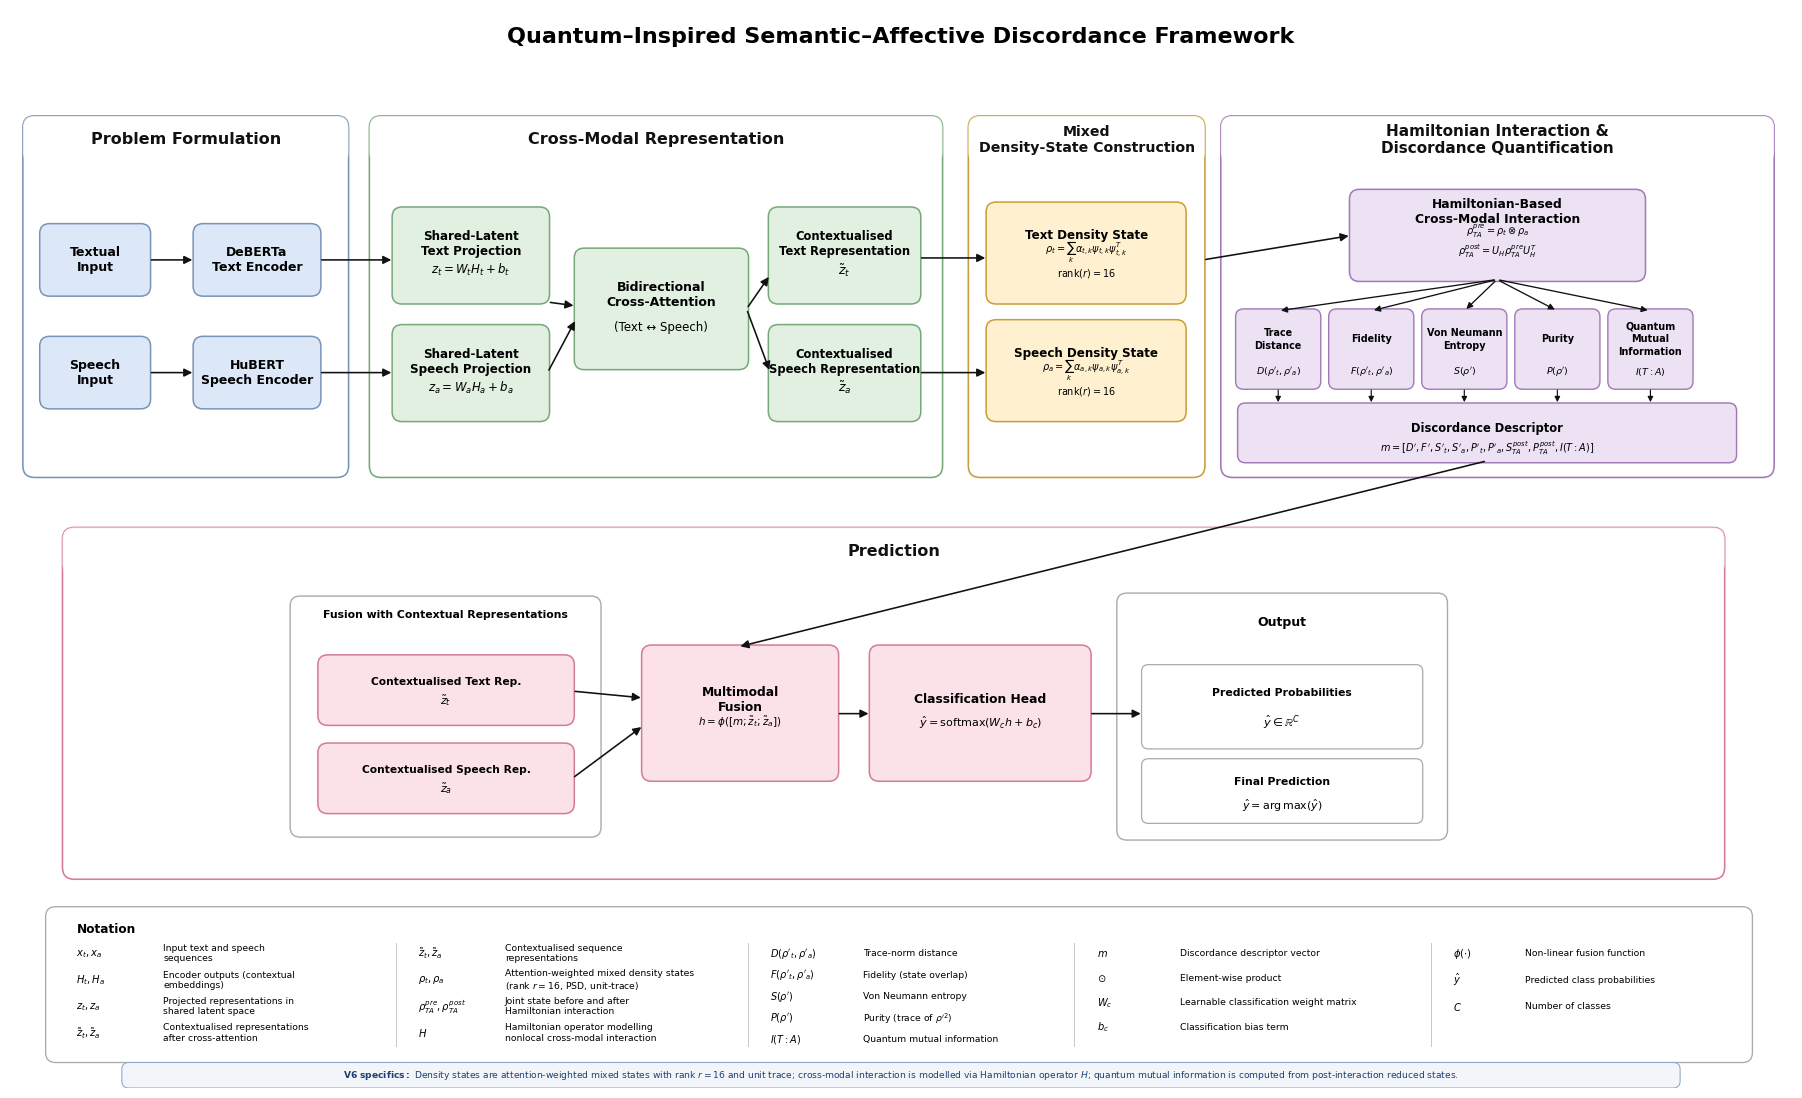

In [ ]:
# ============================================================
# QUANTUM-INSPIRED SEMANTIC–AFFECTIVE DISCORDANCE FRAMEWORK
# Corrected mixed-state + Hamiltonian interaction formulation
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, FancyArrowPatch
from matplotlib.lines import Line2D
import matplotlib as mpl


# ============================================================
# GLOBAL STYLE
# ============================================================

mpl.rcParams["font.family"] = "DejaVu Sans"
mpl.rcParams["mathtext.fontset"] = "dejavusans"
mpl.rcParams["axes.unicode_minus"] = False


FIG_W = 18
FIG_H = 11


fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))

ax.set_xlim(0, 18)
ax.set_ylim(0, 11)
ax.axis("off")


# ============================================================
# COLOUR PALETTE
# ============================================================

BLUE = "#DCE8F8"
BLUE_EDGE = "#7894B8"

GREEN = "#E1F0E0"
GREEN_EDGE = "#76A878"

YELLOW = "#FFF1CF"
YELLOW_EDGE = "#C89D37"

PURPLE = "#EDE1F4"
PURPLE_EDGE = "#A179B6"

PINK = "#FBE1E8"
PINK_EDGE = "#D47C91"

GRAY = "#F5F5F5"
GRAY_EDGE = "#AAAAAA"

WHITE = "#FFFFFF"
BLACK = "#111111"


# ============================================================
# DRAWING HELPERS
# ============================================================

def rounded_box(
    x, y, w, h,
    facecolor=WHITE,
    edgecolor=BLACK,
    lw=1.2,
    radius=0.12,
    zorder=2
):
    patch = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle=f"round,pad=0.02,rounding_size={radius}",
        linewidth=lw,
        edgecolor=edgecolor,
        facecolor=facecolor,
        zorder=zorder
    )

    ax.add_patch(patch)
    return patch


def section_box(
    x, y, w, h, title,
    facecolor=WHITE,
    edgecolor=BLACK,
    title_color=BLACK,
    title_y_offset=0.15,
    title_size=11.5,
    lw=1.15
):

    # Main section
    rounded_box(
        x, y, w, h,
        facecolor=facecolor,
        edgecolor=edgecolor,
        lw=lw,
        radius=0.12,
        zorder=0
    )

    # Header strip
    header_h = 0.45

    header = FancyBboxPatch(
        (x, y+h-header_h),
        w,
        header_h,
        boxstyle="round,pad=0.02,rounding_size=0.12",
        linewidth=0,
        facecolor=facecolor,
        alpha=0.75,
        zorder=0.5
    )

    ax.add_patch(header)

    # Hide lower rounded corners of header
    ax.add_patch(
        Rectangle(
            (x, y+h-header_h),
            w,
            header_h*0.45,
            facecolor=facecolor,
            edgecolor="none",
            zorder=0.6
        )
    )

    ax.text(
        x+w/2,
        y+h-header_h/2,
        title,
        ha="center",
        va="center",
        fontsize=title_size,
        fontweight="bold",
        color=title_color,
        zorder=5
    )


def text_box(
    x, y, w, h,
    title,
    subtitle=None,
    equation=None,
    facecolor=WHITE,
    edgecolor=BLACK,
    title_size=9.5,
    subtitle_size=8.5,
    equation_size=9.5,
    lw=1.1
):

    rounded_box(
        x, y, w, h,
        facecolor=facecolor,
        edgecolor=edgecolor,
        lw=lw,
        radius=0.10
    )

    if equation is not None:

        ax.text(
            x+w/2,
            y+h*0.60,
            title,
            ha="center",
            va="center",
            fontsize=title_size,
            fontweight="bold"
        )

        if subtitle:
            ax.text(
                x+w/2,
                y+h*0.27,
                subtitle,
                ha="center",
                va="center",
                fontsize=subtitle_size
            )

        ax.text(
            x+w/2,
            y+h*0.43,
            equation,
            ha="center",
            va="center",
            fontsize=equation_size
        )

    elif subtitle is not None:

        ax.text(
            x+w/2,
            y+h*0.62,
            title,
            ha="center",
            va="center",
            fontsize=title_size,
            fontweight="bold"
        )

        ax.text(
            x+w/2,
            y+h*0.34,
            subtitle,
            ha="center",
            va="center",
            fontsize=subtitle_size
        )

    else:

        ax.text(
            x+w/2,
            y+h/2,
            title,
            ha="center",
            va="center",
            fontsize=title_size,
            fontweight="bold"
        )


def arrow(
    x1, y1, x2, y2,
    lw=1.15,
    mutation=12,
    color=BLACK,
    style="-|>",
    zorder=4
):

    a = FancyArrowPatch(
        (x1, y1),
        (x2, y2),
        arrowstyle=style,
        mutation_scale=mutation,
        linewidth=lw,
        color=color,
        connectionstyle="arc3",
        zorder=zorder
    )

    ax.add_patch(a)
    return a


def line(
    x1, y1, x2, y2,
    lw=1.05,
    color=BLACK,
    linestyle="-",
    zorder=3
):

    ax.plot(
        [x1, x2],
        [y1, y2],
        color=color,
        linewidth=lw,
        linestyle=linestyle,
        zorder=zorder
    )


def multiline_center(
    x, y, lines,
    fontsize=8.2,
    weight="normal",
    spacing=0.19
):

    total = (len(lines)-1)*spacing
    start = y + total/2

    for i, txt in enumerate(lines):

        ax.text(
            x,
            start-i*spacing,
            txt,
            ha="center",
            va="center",
            fontsize=fontsize,
            fontweight=weight
        )


# ============================================================
# TITLE
# ============================================================

ax.text(
    9,
    10.72,
    "Quantum–Inspired Semantic–Affective Discordance Framework",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)


# ============================================================
# 1) MULTIMODAL FEATURE ENCODING
# ============================================================

section_box(
    0.15, 6.25, 3.25, 3.65,
    "Problem Formulation",
    facecolor=WHITE,
    edgecolor=BLUE_EDGE,
    title_size=11.5
)


# Textual path
text_box(
    0.32, 8.10, 1.08, 0.70,
    "Textual\nInput",
    facecolor=BLUE,
    edgecolor=BLUE_EDGE,
    title_size=9
)

text_box(
    1.87, 8.10, 1.25, 0.70,
    "DeBERTa\nText Encoder",
    facecolor=BLUE,
    edgecolor=BLUE_EDGE,
    title_size=9
)

arrow(1.40, 8.45, 1.87, 8.45)


# Speech path
text_box(
    0.32, 6.95, 1.08, 0.70,
    "Speech\nInput",
    facecolor=BLUE,
    edgecolor=BLUE_EDGE,
    title_size=9
)

text_box(
    1.87, 6.95, 1.25, 0.70,
    "HuBERT\nSpeech Encoder",
    facecolor=BLUE,
    edgecolor=BLUE_EDGE,
    title_size=9
)

arrow(1.40, 7.30, 1.87, 7.30)


# ============================================================
# 2) CROSS-MODAL REPRESENTATION LEARNING
# ============================================================

section_box(
    3.65, 6.25, 5.75, 3.65,
    "Cross-Modal Representation",
    facecolor=WHITE,
    edgecolor=GREEN_EDGE,
    title_size=11.5
)


# Shared latent text
text_box(
    3.88, 8.02, 1.55, 0.95,
    "Shared-Latent\nText Projection",
    r"$z_t = W_tH_t+b_t$",
    facecolor=GREEN,
    edgecolor=GREEN_EDGE,
    title_size=8.6,
    subtitle_size=8.5,
    equation_size=8.8
)


# Shared latent speech
text_box(
    3.88, 6.82, 1.55, 0.95,
    "Shared-Latent\nSpeech Projection",
    r"$z_a = W_aH_a+b_a$",
    facecolor=GREEN,
    edgecolor=GREEN_EDGE,
    title_size=8.6,
    subtitle_size=8.5,
    equation_size=8.8
)


# Cross attention
text_box(
    5.72, 7.35, 1.72, 1.20,
    "Bidirectional\nCross-Attention",
    "(Text ↔ Speech)",
    facecolor=GREEN,
    edgecolor=GREEN_EDGE,
    title_size=9,
    subtitle_size=8.5
)


# Contextualised text
text_box(
    7.68, 8.02, 1.50, 0.95,
    "Contextualised\nText Representation",
    r"$\tilde{z}_t$",
    facecolor=GREEN,
    edgecolor=GREEN_EDGE,
    title_size=8.3,
    subtitle_size=9
)


# Contextualised speech
text_box(
    7.68, 6.82, 1.50, 0.95,
    "Contextualised\nSpeech Representation",
    r"$\tilde{z}_a$",
    facecolor=GREEN,
    edgecolor=GREEN_EDGE,
    title_size=8.3,
    subtitle_size=9
)


# Input arrows from encoders
arrow(3.12, 8.45, 3.88, 8.45)
arrow(3.12, 7.30, 3.88, 7.30)


# Projection → attention
arrow(5.43, 8.02, 5.72, 7.98)
arrow(5.43, 7.30, 5.72, 7.85)


# Attention → contextualised
arrow(7.44, 7.95, 7.68, 8.30)
arrow(7.44, 7.95, 7.68, 7.30)


# ============================================================
# 3) QUANTUM-INSPIRED DENSITY-STATE CONSTRUCTION
# ============================================================

section_box(
    9.70, 6.25, 2.35, 3.65,
    "Mixed\nDensity-State Construction",
    facecolor=WHITE,
    edgecolor=YELLOW_EDGE,
    title_size=10.2
)


# ------------------------------------------------------------
# Corrected mixed Text density state
# ------------------------------------------------------------

text_box(
    9.88, 8.02, 1.98, 1.00,
    "Text Density State\n",
    equation=(
        r"$\rho_t=\sum_k \alpha_{t,k}\psi_{t,k}\psi_{t,k}^{T}$"
        "\n"
        r"$\mathrm{rank}(r)=16$"
    ),
    facecolor=YELLOW,
    edgecolor=YELLOW_EDGE,
    title_size=8.6,
    equation_size=7.0
)


# ------------------------------------------------------------
# Corrected mixed Speech density state
# ------------------------------------------------------------

text_box(
    9.88, 6.82, 1.98, 1.00,
    "Speech Density State\n",
    equation=(
        r"$\rho_a=\sum_k \alpha_{a,k}\psi_{a,k}\psi_{a,k}^{T}$"
        "\n"
        r"$\mathrm{rank}(r)=16$"
    ),
    facecolor=YELLOW,
    edgecolor=YELLOW_EDGE,
    title_size=8.6,
    equation_size=7.0
)


# Arrows contextual → states
arrow(9.18, 8.47, 9.88, 8.47)
arrow(9.18, 7.30, 9.88, 7.30)


# ============================================================
# 4) V6 HAMILTONIAN INTERACTION & DISCORDANCE
# ============================================================

section_box(
    12.25, 6.25, 5.55, 3.65,
    "Hamiltonian Interaction &\nDiscordance Quantification",
    facecolor=WHITE,
    edgecolor=PURPLE_EDGE,
    title_size=11
)


# ------------------------------------------------------------
# Corrected Hamiltonian interaction
# ------------------------------------------------------------

text_box(
    13.55, 8.25, 2.95, 0.90,
    "Hamiltonian-Based\nCross-Modal Interaction\n\n",
    equation=(
        r"$\rho_{TA}^{pre}=\rho_t\otimes\rho_a$"
        "\n"
        r"$\rho_{TA}^{post}=U_H\rho_{TA}^{pre}U_H^{T}$"
    ),
    facecolor=PURPLE,
    edgecolor=PURPLE_EDGE,
    title_size=8.8,
    equation_size=7.0
)


# Connect state construction to Hamiltonian
arrow(12.05, 8.45, 13.55, 8.70)


# ------------------------------------------------------------
# Metric boxes
# ------------------------------------------------------------

metric_y = 7.15
metric_h = 0.78
metric_w = 0.82

metric_x = [
    12.40,
    13.34,
    14.28,
    15.22,
    16.16
]

metric_titles = [
    ["Trace", "Distance"],
    ["Fidelity"],
    ["Von Neumann", "Entropy"],
    ["Purity"],
    ["Quantum", "Mutual", "Information"]
]

# Post-interaction metrics
metric_eqs = [
    r"$D(\rho'_t,\rho'_a)$",
    r"$F(\rho'_t,\rho'_a)$",
    r"$S(\rho')$",
    r"$P(\rho')$",
    r"$I(T:A)$"
]


for x, title_lines, eq in zip(metric_x, metric_titles, metric_eqs):

    rounded_box(
        x, metric_y,
        metric_w, metric_h,
        facecolor=PURPLE,
        edgecolor=PURPLE_EDGE,
        lw=1.0,
        radius=0.08
    )

    multiline_center(
        x+metric_w/2,
        metric_y+0.49,
        title_lines,
        fontsize=6.9,
        weight="bold",
        spacing=0.13
    )

    ax.text(
        x+metric_w/2,
        metric_y+0.16,
        eq,
        ha="center",
        va="center",
        fontsize=6.8
    )

    # Hamiltonian → metric
    arrow(
        15.02,
        8.25,
        x+metric_w/2,
        metric_y+metric_h,
        lw=0.95,
        mutation=9
    )


# ============================================================
# DISCORDANCE DESCRIPTOR
# ============================================================

rounded_box(
    12.42, 6.40, 5.00, 0.57,
    facecolor=PURPLE,
    edgecolor=PURPLE_EDGE,
    lw=1.05,
    radius=0.08
)

ax.text(
    14.92,
    6.73,
    "Discordance Descriptor",
    ha="center",
    va="center",
    fontsize=8.3,
    fontweight="bold"
)

ax.text(
    14.92,
    6.53,
    r"$m=[D',F',S'_t,S'_a,P'_t,P'_a,S_{TA}^{post},P_{TA}^{post},I(T:A)]$",
    ha="center",
    va="center",
    fontsize=7.0
)


# Metrics → descriptor
for x in metric_x:

    arrow(
        x+metric_w/2,
        metric_y,
        x+metric_w/2,
        6.97,
        lw=0.85,
        mutation=8
    )


# ============================================================
# 5) PREDICTION
# ============================================================

section_box(
    0.55, 2.15, 16.75, 3.55,
    "Prediction",
    facecolor=WHITE,
    edgecolor=PINK_EDGE,
    title_size=11.5
)


# ------------------------------------------------------------
# Fusion with contextual representations container
# ------------------------------------------------------------

rounded_box(
    2.85, 2.58, 3.10, 2.42,
    facecolor=WHITE,
    edgecolor=GRAY_EDGE,
    lw=1.0,
    radius=0.10
)

ax.text(
    4.40,
    4.83,
    "Fusion with Contextual Representations",
    ha="center",
    va="center",
    fontsize=7.8,
    fontweight="bold"
)


# Contextualised text representation
text_box(
    3.13, 3.72, 2.55, 0.68,
    "Contextualised Text Rep.",
    r"$\tilde{z}_t$",
    facecolor=PINK,
    edgecolor=PINK_EDGE,
    title_size=7.7,
    subtitle_size=8
)


# Contextualised speech representation
text_box(
    3.13, 2.82, 2.55, 0.68,
    "Contextualised Speech Rep.",
    r"$\tilde{z}_a$",
    facecolor=PINK,
    edgecolor=PINK_EDGE,
    title_size=7.7,
    subtitle_size=8
)


# ------------------------------------------------------------
# Multimodal fusion
# ------------------------------------------------------------

text_box(
    6.40, 3.15, 1.95, 1.35,
    "Multimodal\nFusion",
    equation=r"$h=\phi([m;\tilde{z}_t;\tilde{z}_a])$",
    facecolor=PINK,
    edgecolor=PINK_EDGE,
    title_size=8.8,
    equation_size=7.5
)


# ------------------------------------------------------------
# Classification head
# ------------------------------------------------------------

text_box(
    8.70, 3.15, 2.20, 1.35,
    "Classification Head",
    equation=r"$\hat{y}=\mathrm{softmax}(W_ch+b_c)$",
    facecolor=PINK,
    edgecolor=PINK_EDGE,
    title_size=8.8,
    equation_size=8
)


# ------------------------------------------------------------
# Output container
# ------------------------------------------------------------

rounded_box(
    11.20, 2.55, 3.30, 2.48,
    facecolor=WHITE,
    edgecolor=GRAY_EDGE,
    lw=1.0,
    radius=0.10
)

ax.text(
    12.85,
    4.75,
    "Output",
    ha="center",
    va="center",
    fontsize=9,
    fontweight="bold"
)


# Predicted probabilities
rounded_box(
    11.45, 3.48, 2.80, 0.82,
    facecolor=WHITE,
    edgecolor=GRAY_EDGE,
    lw=0.9,
    radius=0.07
)

ax.text(
    12.85,
    4.03,
    "Predicted Probabilities",
    ha="center",
    va="center",
    fontsize=7.8,
    fontweight="bold"
)

ax.text(
    12.85,
    3.73,
    r"$\hat{y}\in\mathbb{R}^{C}$",
    ha="center",
    va="center",
    fontsize=8.2
)


# Final prediction
rounded_box(
    11.45, 2.72, 2.80, 0.62,
    facecolor=WHITE,
    edgecolor=GRAY_EDGE,
    lw=0.9,
    radius=0.07
)

ax.text(
    12.85,
    3.12,
    "Final Prediction",
    ha="center",
    va="center",
    fontsize=7.8,
    fontweight="bold"
)

ax.text(
    12.85,
    2.88,
    r"$\hat{y}=\arg\max(\hat{y})$",
    ha="center",
    va="center",
    fontsize=7.9
)


# ============================================================
# SECTION 5 CONNECTIONS

# Discordance descriptor → Multimodal Fusion
arrow(
    14.92,
    6.40,
    7.35,
    4.50
)


# Contextualised text → Multimodal Fusion
arrow(
    5.68,
    4.05,
    6.40,
    3.98
)


# Contextualised speech → Multimodal Fusion
arrow(
    5.68,
    3.16,
    6.40,
    3.70
)


# Multimodal Fusion → Classification Head
arrow(
    8.35,
    3.82,
    8.70,
    3.82
)


# Classification Head → Output
arrow(
    10.90,
    3.82,
    11.45,
    3.82
)


# ============================================================
# NOTATION PANEL

rounded_box(
    0.38, 0.28, 17.20, 1.55,
    facecolor=WHITE,
    edgecolor=GRAY_EDGE,
    lw=0.95,
    radius=0.10
)

ax.text(
    0.68,
    1.62,
    "Notation",
    ha="left",
    va="center",
    fontsize=8.7,
    fontweight="bold"
)


# Vertical separators
for x in [3.90, 7.45, 10.75, 14.35]:

    line(
        x, 0.43, x, 1.48,
        lw=0.7,
        color="#C9C9C9"
    )


# ============================================================
# Column 1

notation1 = [
    (r"$x_t,x_a$", "Input text and speech\nsequences"),
    (r"$H_t,H_a$", "Encoder outputs (contextual\nembeddings)"),
    (r"$z_t,z_a$", "Projected representations in\nshared latent space"),
    (r"$\tilde{z}_t,\tilde{z}_a$", "Contextualised representations\nafter cross-attention"),
]

yy = 1.37

for symbol, desc in notation1:

    ax.text(
        0.67,
        yy,
        symbol,
        ha="left",
        va="center",
        fontsize=7.2
    )

    ax.text(
        1.55,
        yy,
        desc,
        ha="left",
        va="center",
        fontsize=6.7
    )

    yy -= 0.27


# ============================================================
# Column 2

notation2 = [
    (
        r"$\tilde{z}_t,\tilde{z}_a$",
        "Contextualised sequence\nrepresentations"
    ),
    (
        r"$\rho_t,\rho_a$",
        "Attention-weighted mixed density states\n"
        "(rank $r=16$, PSD, unit-trace)"
    ),
    (
        r"$\rho_{TA}^{pre},\rho_{TA}^{post}$",
        "Joint state before and after\n"
        "Hamiltonian interaction"
    ),
    (
        r"$H$",
        "Hamiltonian operator modelling\n"
        "nonlocal cross-modal interaction"
    ),
]

yy = 1.37

for symbol, desc in notation2:

    ax.text(
        4.12,
        yy,
        symbol,
        ha="left",
        va="center",
        fontsize=7.2
    )

    ax.text(
        5.00,
        yy,
        desc,
        ha="left",
        va="center",
        fontsize=6.7
    )

    yy -= 0.27


# ============================================================
# Column 3

notation3 = [
    (
        r"$D(\rho'_t,\rho'_a)$",
        "Trace-norm distance"
    ),
    (
        r"$F(\rho'_t,\rho'_a)$",
        "Fidelity (state overlap)"
    ),
    (
        r"$S(\rho')$",
        "Von Neumann entropy"
    ),
    (
        r"$P(\rho')$",
        r"Purity (trace of $\rho'^2$)"
    ),
    (
        r"$I(T:A)$",
        "Quantum mutual information"
    ),
]

yy = 1.37

for symbol, desc in notation3:

    ax.text(
        7.68,
        yy,
        symbol,
        ha="left",
        va="center",
        fontsize=7.0
    )

    ax.text(
        8.62,
        yy,
        desc,
        ha="left",
        va="center",
        fontsize=6.7
    )

    yy -= 0.22


# ============================================================
# Column 4

notation4 = [
    (
        r"$m$",
        "Discordance descriptor vector"
    ),
    (
        r"$\odot$",
        "Element-wise product"
    ),
    (
        r"$W_c$",
        "Learnable classification weight matrix"
    ),
    (
        r"$b_c$",
        "Classification bias term"
    ),
]

yy = 1.37

for symbol, desc in notation4:

    ax.text(
        10.98,
        yy,
        symbol,
        ha="left",
        va="center",
        fontsize=7.1
    )

    ax.text(
        11.82,
        yy,
        desc,
        ha="left",
        va="center",
        fontsize=6.7
    )

    yy -= 0.25


# ============================================================
# Column 5

notation5 = [
    (
        r"$\phi(\cdot)$",
        "Non-linear fusion function"
    ),
    (
        r"$\hat{y}$",
        "Predicted class probabilities"
    ),
    (
        r"$C$",
        "Number of classes"
    ),
]

yy = 1.37

for symbol, desc in notation5:

    ax.text(
        14.58,
        yy,
        symbol,
        ha="left",
        va="center",
        fontsize=7.1
    )

    ax.text(
        15.30,
        yy,
        desc,
        ha="left",
        va="center",
        fontsize=6.7
    )

    yy -= 0.27


# ============================================================
# V6 SPECIFICATION BAR

rounded_box(
    1.15, 0.02, 15.70, 0.22,
    facecolor="#F2F5FA",
    edgecolor="#8EA7CA",
    lw=0.75,
    radius=0.07
)

ax.text(
    9.00,
    0.13,
    r"$\bf{V6\ specifics:}$ "
    r"Density states are attention-weighted mixed states "
    r"with rank $r=16$ and unit trace; "
    r"cross-modal interaction is modelled via Hamiltonian operator $H$; "
    r"quantum mutual information is computed from post-interaction "
    r"reduced states.",
    ha="center",
    va="center",
    fontsize=6.6,
    color="#1F3F70"
)

# Make sure axes don't introduce whitespace
plt.subplots_adjust(
    left=0.005,
    right=0.995,
    top=0.985,
    bottom=0.005
)


# High-resolution raster
plt.savefig(
    "discordance_architecture.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white"
)

plt.savefig(
    "discordance_architecture.svg",
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white"
)

plt.savefig(
    "discordance_architecture.pdf",
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white"
)


plt.show()